# Functional distortion examples

Each example shows both continuous maps on the original Mapper graphs and prints the two height errors, distortion (D), and their maximum (functional distortion) in grid units. Preprocessing includes graph setup and fitting the interleaving when used. The total also includes FD map construction and distortion computation. Plotting happens outside the timed stages. The cost of each map pair gives an upper bound on the functional distortion distance.

In [1]:
import sys
from pathlib import Path

# Make project imports available when Jupyter starts in experiment/.
if Path.cwd().name == "experiment":
    sys.path.insert(0, str(Path.cwd().parent))

from fractions import Fraction as Fr
from time import perf_counter
import matplotlib.pyplot as plt
from cereeberus import Interleave, MapperGraph
from cereeberus.data import ex_mappergraphs as ex, ex_reebgraphs as exr
from core.distortion import functional_distortion
from core.fd_map_build import maps_from_interleave
from core.functionaldistortiongraph import FunctionalDistortionGraph
from visualize.fd_metromaps import draw_fd_maps


### Shared example helpers

In [2]:
def make_graph(nodes, edges):
    M = MapperGraph()
    for name, h in nodes:
        M.add_node(name, h, reset_pos=False)
    for u, v in edges:
        M.add_edge(u, v, reset_pos=False)
    return M


def show_maps(title, F, G, Phi, Psi, posF=None, posG=None,
              names=("F", "G"), figsize=(11, 8), plot=True, *, preprocessing_time, construction_time):
    start = perf_counter()
    result = functional_distortion(F, G, Phi, Psi)
    distortion_time = perf_counter() - start
    if plot:
        fig = draw_fd_maps(Phi, Psi, posF=posF, posG=posG,
                               names=names, figsize=figsize, warn_color_reuse=False)
        fig.suptitle(title)
        plt.show()
    print(f"maxₓ |f(x) − g(Φ(x))| = {float(round(result['height_Phi_units'], 3))}")
    print(f"maxᵧ |g(y) − f(Ψ(y))| = {float(round(result['height_Psi_units'], 3))}")
    print(f"D = {float(round(result['D_units'], 3))}")
    print(f"Functional distortion = {float(round(result['FD_units'], 3))}")
    total_time = preprocessing_time + construction_time + distortion_time
    print(
        f"Elapsed time: total {total_time:.3f} s (preprocessing: {preprocessing_time:.3f} s, "
        f"FD map construction: {construction_time:.3f} s, "
        f"distortion computation: {distortion_time:.3f} s)"
    )
    return result


def ilp_example(title, F_nodes, F_edges, G_nodes, G_edges, posF, posG,
                names=("F", "G"), figsize=(11, 8), paths="min_span", plot=True):
    start = perf_counter()
    interleaving = Interleave(make_graph(F_nodes, F_edges), make_graph(G_nodes, G_edges))
    n = interleaving.fit()
    # print("Interleaving parameter:", n)
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    maps = maps_from_interleave(interleaving, seed=0, points="close", paths=paths)
    construction_time = perf_counter() - start
    return show_maps(title, *(maps[k] for k in ("F", "G", "Phi", "Psi")),
                     posF, posG, names, figsize, plot, preprocessing_time=preprocessing_time,
                     construction_time=construction_time)


def _loop_data():
    loop_n = [("v", 0), ("a", 1), ("b", 1), ("w", 2)]
    loop_e = [("v", "a"), ("v", "b"), ("a", "w"), ("b", "w")]
    pos_loop = {"v": (0, 0), "a": (-1, 1), "b": (1, 1), "w": (0, 2), "t": (0, 3)}
    return (loop_n, loop_e, pos_loop)


def _y_data():
    YF_n = [("f0", 0), ("f1", 1), ("f2", 2), ("j", 3), ("L4", 4), ("L5", 5), ("R4", 4)]
    YF_e = [
        ("f0", "f1"),
        ("f1", "f2"),
        ("f2", "j"),
        ("j", "L4"),
        ("L4", "L5"),
        ("j", "R4"),
    ]
    YG_n = [("g5", 5), ("g4", 4), ("g3", 3), ("q", 2), ("b1", 1), ("b0", 0), ("c1", 1)]
    YG_e = [
        ("g5", "g4"),
        ("g4", "g3"),
        ("g3", "q"),
        ("q", "b1"),
        ("b1", "b0"),
        ("q", "c1"),
    ]
    posF = {
        "f0": (0, 0),
        "f1": (0, 1),
        "f2": (0, 2),
        "j": (0, 3),
        "L4": (-1, 4),
        "L5": (-1, 5),
        "R4": (1, 4),
    }
    posG = {
        "g5": (0, 5),
        "g4": (0, 4),
        "g3": (0, 3),
        "q": (0, 2),
        "b1": (-1, 1),
        "b0": (-1, 0),
        "c1": (1, 1),
    }
    return (YF_n, YF_e, YG_n, YG_e, posF, posG)

## Square loop folded onto an edge

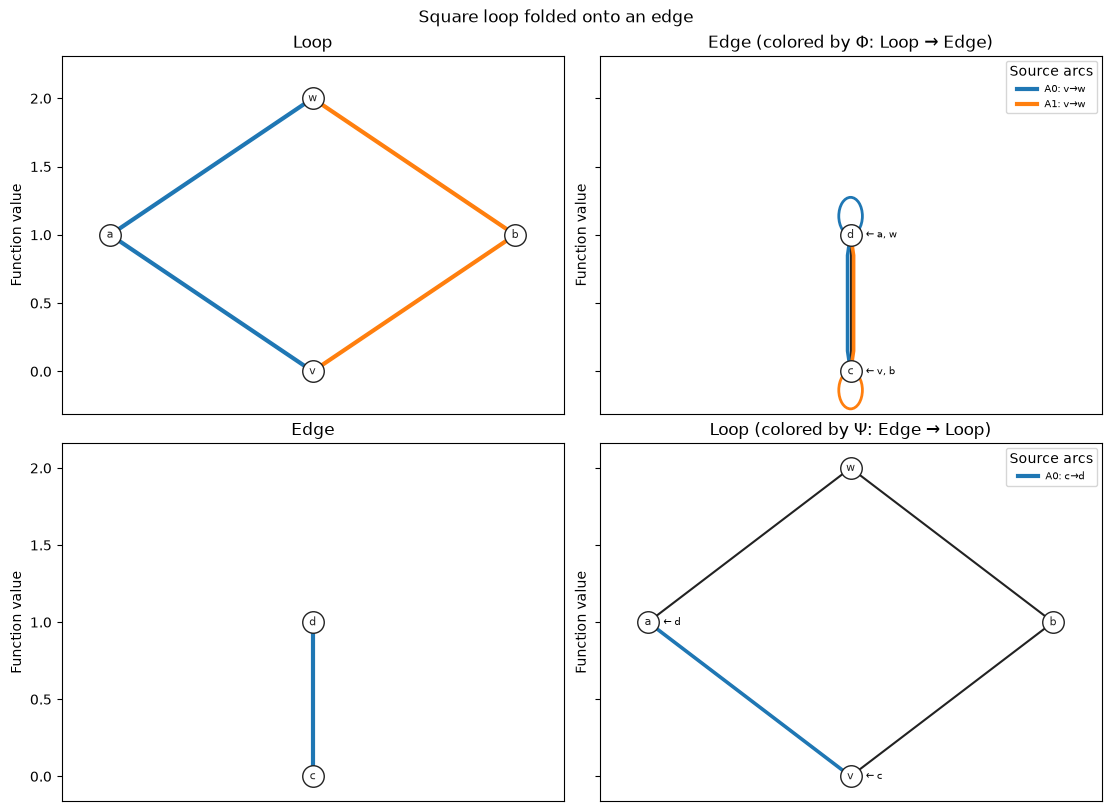

maxₓ |f(x) − g(Φ(x))| = 1.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.75
Functional distortion = 1.0
Elapsed time: total 0.327 s (preprocessing: 0.323 s, FD map construction: 0.000 s, distortion computation: 0.003 s)


In [3]:
def square_loop_example():
    """Example 2: the square loop v-a-w-b-v folded onto one edge cd."""
    start = perf_counter()
    F = FunctionalDistortionGraph.from_edges({"v": 0, "a": 1, "b": 1, "w": 2}, [("v", "a"), ("v", "b"), ("a", "w"), ("b", "w")])
    G = FunctionalDistortionGraph.from_edges({"c": 0, "d": 1}, [("c", "d")])
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    Phi = F.map_to(G, {"v": "c", "a": "d", "b": "c", "w": "d"})
    Psi = G.map_to(F, {"c": "v", "d": "a"})
    construction_time = perf_counter() - start
    return F, G, Phi, Psi, preprocessing_time, construction_time


F, G, Phi, Psi, preprocessing_time, construction_time = square_loop_example()
square_result = show_maps(
    "Square loop folded onto an edge", F, G, Phi, Psi,
    posF={"v": (0, 0), "a": (-1, 1), "b": (1, 1), "w": (0, 2)},
    posG={"c": (0, 0), "d": (0, 1)}, names=("Loop", "Edge"), preprocessing_time=preprocessing_time,
    construction_time=construction_time,
)
assert square_result["D_units"] == Fr(3, 4)

## Identical graphs

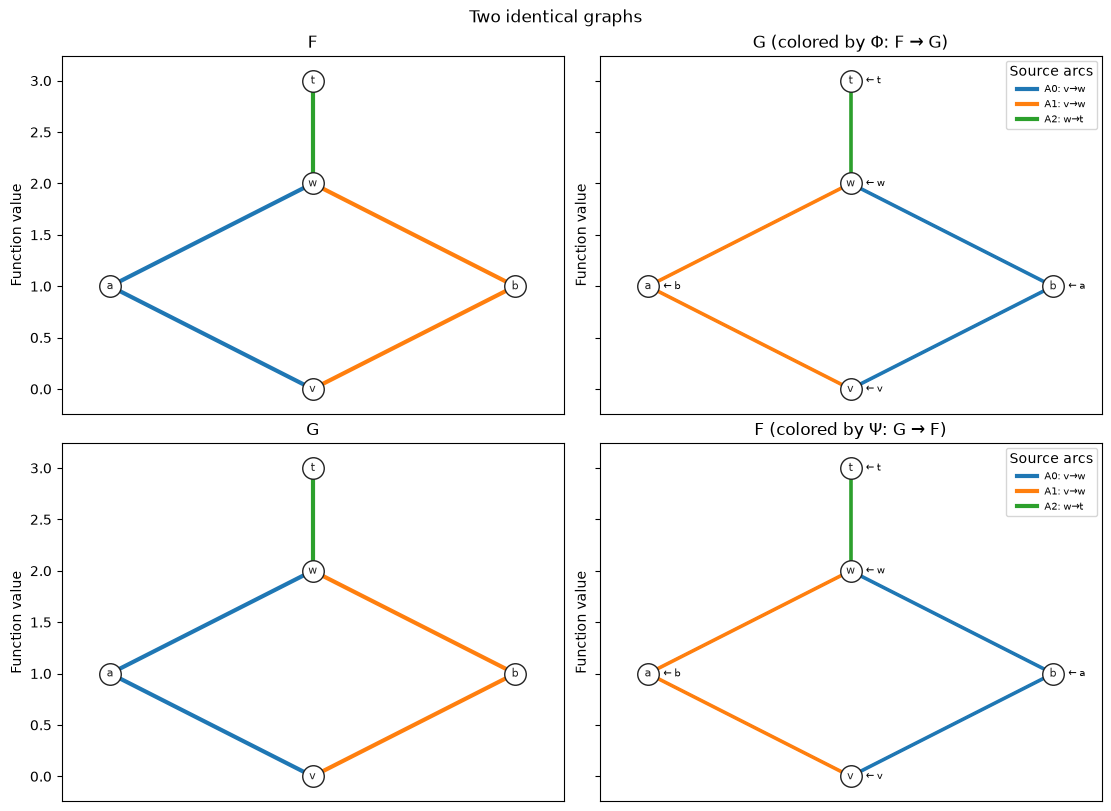

maxₓ |f(x) − g(Φ(x))| = 0.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.0
Functional distortion = 0.0
Elapsed time: total 0.132 s (preprocessing: 0.130 s, FD map construction: 0.001 s, distortion computation: 0.001 s)


{'height_Phi_units': Fraction(0, 1),
 'height_Psi_units': Fraction(0, 1),
 'D_units': Fraction(0, 1),
 'FD_units': Fraction(0, 1),
 'height_Phi': Fraction(0, 1),
 'height_Psi': Fraction(0, 1),
 'D': Fraction(0, 1),
 'FD': Fraction(0, 1),
 'witness_height_Phi': (('v', 'v'), ('v', 'v')),
 'witness_height_Psi': (('v', 'v'), ('v', 'v')),
 'witness_D': {'segA': CSegment(origin='Phi', edge=('v', 'a'), index=0, F=Side(edge=('v', 'a'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('v', 'b'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1))),
  'segB': CSegment(origin='Phi', edge=('v', 'a'), index=0, F=Side(edge=('v', 'a'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('v', 'b'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1))),
  'sigma': Fraction(0, 1),
  'tau': Fraction(0, 1),
  'pair': ((('v', 'v'), ('v', 'v')), (('v', 'v'), ('v', 'v'))),
  'd_f': Fraction(0, 1),
  'd_g': Fraction(0, 1)},
 'delta': 1,
 'pairs_total': 55,
 'pairs_visited': 1,
 'D_ex

In [4]:
def identity(*, plot=True):
    (loop_n, loop_e, pos_loop) = _loop_data()
    r = ilp_example(
        "Two identical graphs",
        loop_n + [("t", 3)],
        loop_e + [("w", "t")],
        loop_n + [("t", 3)],
        loop_e + [("w", "t")],
        pos_loop,
        pos_loop,
        paths="fewest_edges",
        plot=plot,
    )
    assert (r["height_Phi_units"], r["height_Psi_units"], r["D_units"]) == (0, 0, 0)
    return r

identity()

## Line and loop

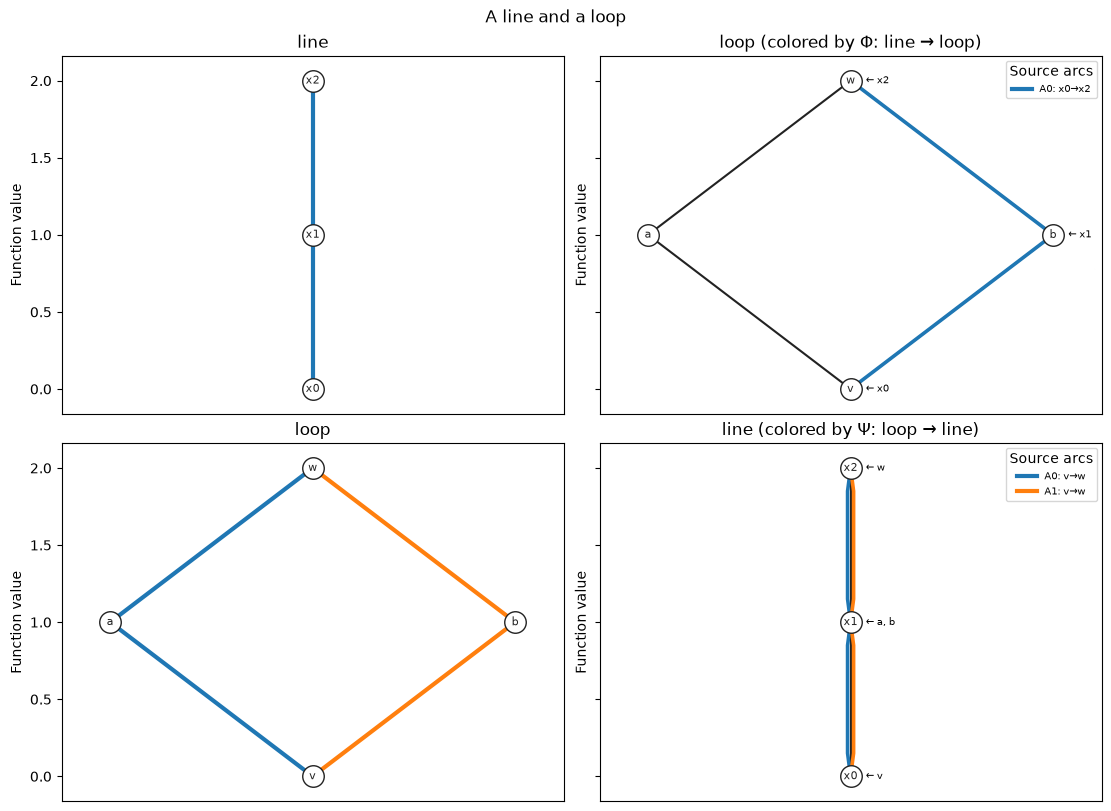

maxₓ |f(x) − g(Φ(x))| = 0.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.5
Functional distortion = 0.5
Elapsed time: total 0.132 s (preprocessing: 0.124 s, FD map construction: 0.007 s, distortion computation: 0.002 s)


{'height_Phi_units': Fraction(0, 1),
 'height_Psi_units': Fraction(0, 1),
 'D_units': Fraction(1, 2),
 'FD_units': Fraction(1, 2),
 'height_Phi': Fraction(0, 1),
 'height_Psi': Fraction(0, 1),
 'D': Fraction(1, 2),
 'FD': Fraction(1, 2),
 'witness_height_Phi': (('v', 'x0'), ('v', 'v')),
 'witness_height_Psi': (('v', 'v'), ('v', 'x0')),
 'witness_D': {'segA': CSegment(origin='Psi', edge=('v', 'a'), index=0, F=Side(edge=('x0', 'x1'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('v', 'a'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1))),
  'segB': CSegment(origin='Psi', edge=('v', 'b'), index=0, F=Side(edge=('x0', 'x1'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('v', 'b'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1))),
  'sigma': Fraction(1, 1),
  'tau': Fraction(1, 1),
  'pair': ((('v', 'x1'), ('v', 'a')), (('v', 'x1'), ('v', 'b'))),
  'd_f': Fraction(0, 1),
  'd_g': Fraction(1, 1)},
 'delta': 1,
 'pairs_total': 21,
 'pairs_visited': 4

In [5]:
def line_loop(*, plot=True):
    (loop_n, loop_e, pos_loop) = _loop_data()
    r = ilp_example(
        "A line and a loop",
        [("x0", 0), ("x1", 1), ("x2", 2)],
        [("x0", "x1"), ("x1", "x2")],
        loop_n,
        loop_e,
        {"x0": (0, 0), "x1": (0, 1), "x2": (0, 2)},
        {"v": (0, 0), "a": (-1, 1), "b": (1, 1), "w": (0, 2)},
        names=("line", "loop"),
        plot=plot,
    )
    assert (r["height_Phi_units"], r["height_Psi_units"], r["D_units"]) == (
        0,
        0,
        Fr(1, 2),
    )
    return r

line_loop()

## Loop and edge from an interleaving

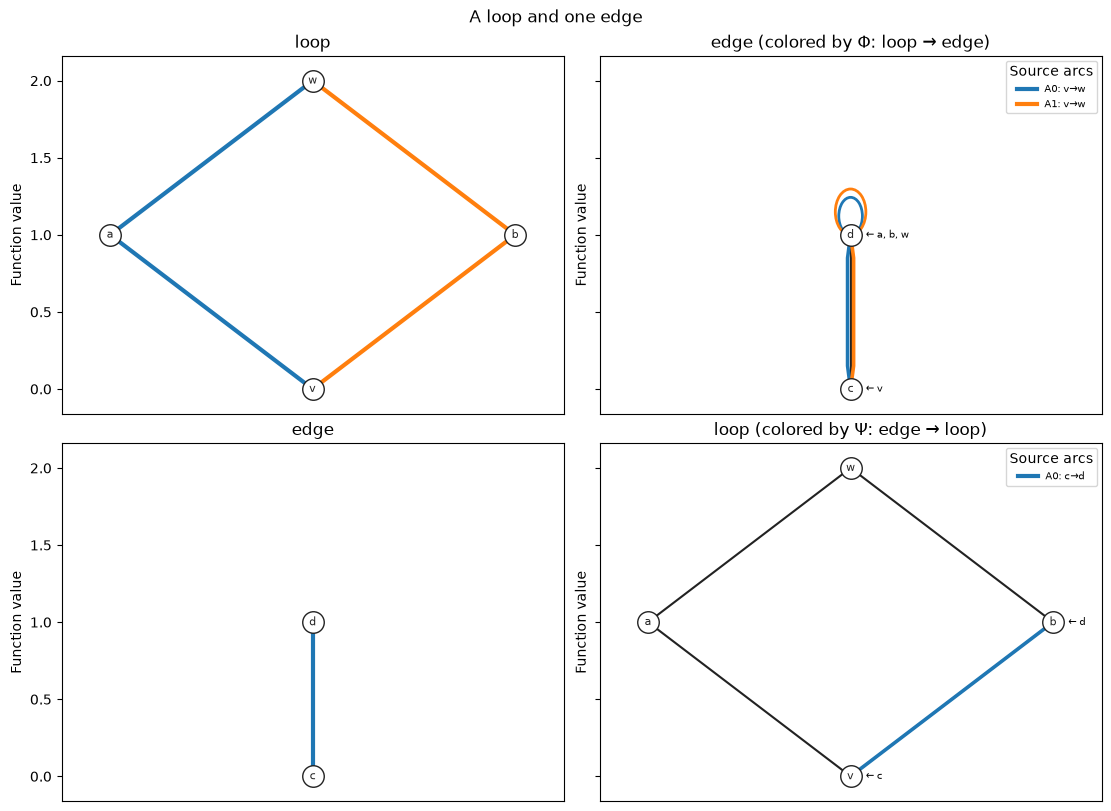

maxₓ |f(x) − g(Φ(x))| = 1.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.5
Functional distortion = 1.0
Elapsed time: total 0.081 s (preprocessing: 0.072 s, FD map construction: 0.005 s, distortion computation: 0.003 s)


{'height_Phi_units': Fraction(1, 1),
 'height_Psi_units': Fraction(0, 1),
 'D_units': Fraction(1, 2),
 'FD_units': Fraction(1, 1),
 'height_Phi': Fraction(1, 1),
 'height_Psi': Fraction(0, 1),
 'D': Fraction(1, 2),
 'FD': Fraction(1, 1),
 'witness_height_Phi': (('v', 'w'), ('v', 'd')),
 'witness_height_Psi': (('v', 'c'), ('v', 'v')),
 'witness_D': {'segA': CSegment(origin='Phi', edge=('v', 'a'), index=0, F=Side(edge=('v', 'a'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('c', 'd'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1))),
  'segB': CSegment(origin='Phi', edge=('a', 'w'), index=0, F=Side(edge=('a', 'w'), vertex=None, h0=Fraction(1, 1), h1=Fraction(2, 1)), G=Side(edge=None, vertex='d', h0=Fraction(1, 1), h1=Fraction(1, 1))),
  'sigma': Fraction(0, 1),
  'tau': Fraction(1, 1),
  'pair': ((('v', 'v'), ('v', 'c')), (('v', 'w'), ('v', 'd'))),
  'd_f': Fraction(2, 1),
  'd_g': Fraction(1, 1)},
 'delta': 1,
 'pairs_total': 15,
 'pairs_visited': 15,
 'D_exact': 

In [6]:
def loop_edge(*, plot=True):
    (loop_n, loop_e, pos_loop) = _loop_data()
    r = ilp_example(
        "A loop and one edge",
        loop_n,
        loop_e,
        [("c", 0), ("d", 1)],
        [("c", "d")],
        {"v": (0, 0), "a": (-1, 1), "b": (1, 1), "w": (0, 2)},
        {"c": (0, 0), "d": (0, 1)},
        names=("loop", "edge"),
        plot=plot,
    )
    assert (r["height_Phi_units"], r["height_Psi_units"], r["D_units"]) == (
        1,
        0,
        Fr(1, 2),
    )
    return r

loop_edge()

## Y graphs from an interleaving

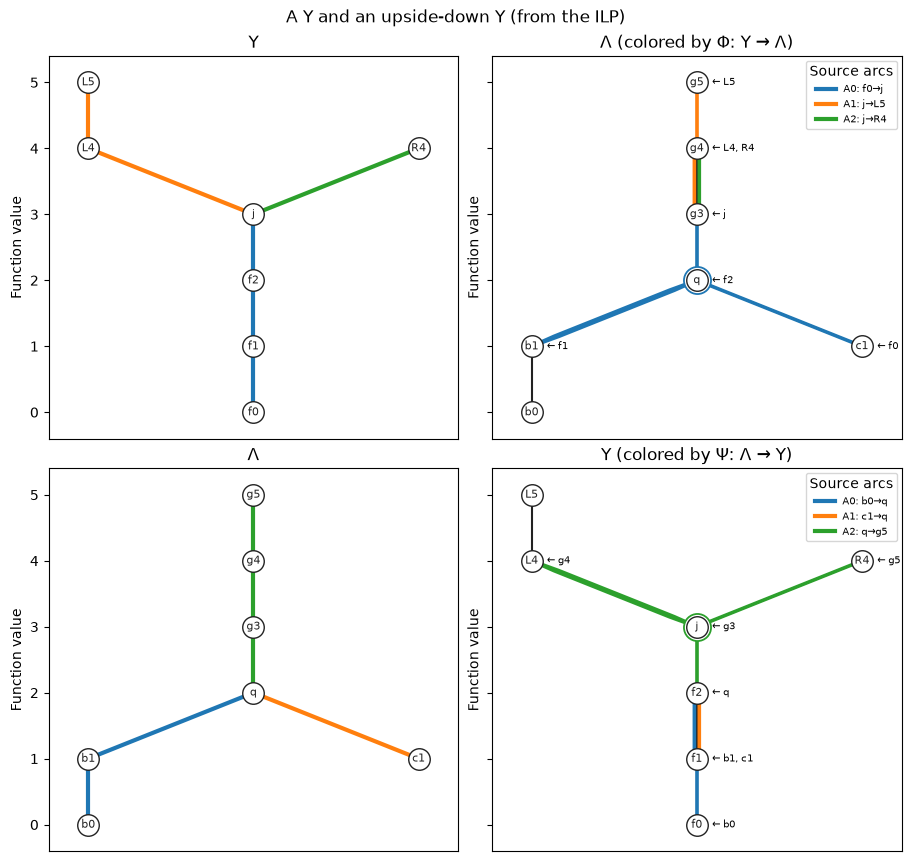

maxₓ |f(x) − g(Φ(x))| = 1.0
maxᵧ |g(y) − f(Ψ(y))| = 1.0
D = 1.0
Functional distortion = 1.0
Elapsed time: total 0.239 s (preprocessing: 0.188 s, FD map construction: 0.014 s, distortion computation: 0.037 s)


{'height_Phi_units': Fraction(2001, 2000),
 'height_Psi_units': Fraction(2001, 2000),
 'D_units': Fraction(1, 1),
 'FD_units': Fraction(2001, 2000),
 'height_Phi': Fraction(2001, 2000),
 'height_Psi': Fraction(2001, 2000),
 'D': Fraction(1, 1),
 'FD': Fraction(2001, 2000),
 'witness_height_Phi': (('e', ('f0', 'f1'), Fraction(1999, 2000)), ('v', 'q')),
 'witness_height_Psi': (('e', ('g4', 'g5'), Fraction(8001, 2000)), ('v', 'j')),
 'witness_D': {'segA': CSegment(origin='Phi', edge=('L4', 'L5'), index=0, F=Side(edge=('L4', 'L5'), vertex=None, h0=Fraction(4, 1), h1=Fraction(5, 1)), G=Side(edge=('g4', 'g5'), vertex=None, h0=Fraction(4, 1), h1=Fraction(5, 1))),
  'segB': CSegment(origin='Psi', edge=('g4', 'g5'), index=1, F=Side(edge=('j', 'R4'), vertex=None, h0=Fraction(3, 1), h1=Fraction(4, 1)), G=Side(edge=('g4', 'g5'), vertex=None, h0=Fraction(8001, 2000), h1=Fraction(5, 1))),
  'sigma': Fraction(1, 1),
  'tau': Fraction(1, 1),
  'pair': ((('v', 'L5'), ('v', 'g5')), (('v', 'R4'), ('v', '

In [7]:
def y_interleaving(*, plot=True):
    (YF_n, YF_e, YG_n, YG_e, posF, posG) = _y_data()
    r = ilp_example(
        "A Y and an upside-down Y (from the ILP)",
        YF_n,
        YF_e,
        YG_n,
        YG_e,
        posF,
        posG,
        names=("Y", "Λ"),
        figsize=(9, 8.5),
        plot=plot,
    )
    assert r["D_units"] == 1 and r["FD_units"] < Fr(101, 100)
    return r

y_interleaving()

## Y graphs with height reversal

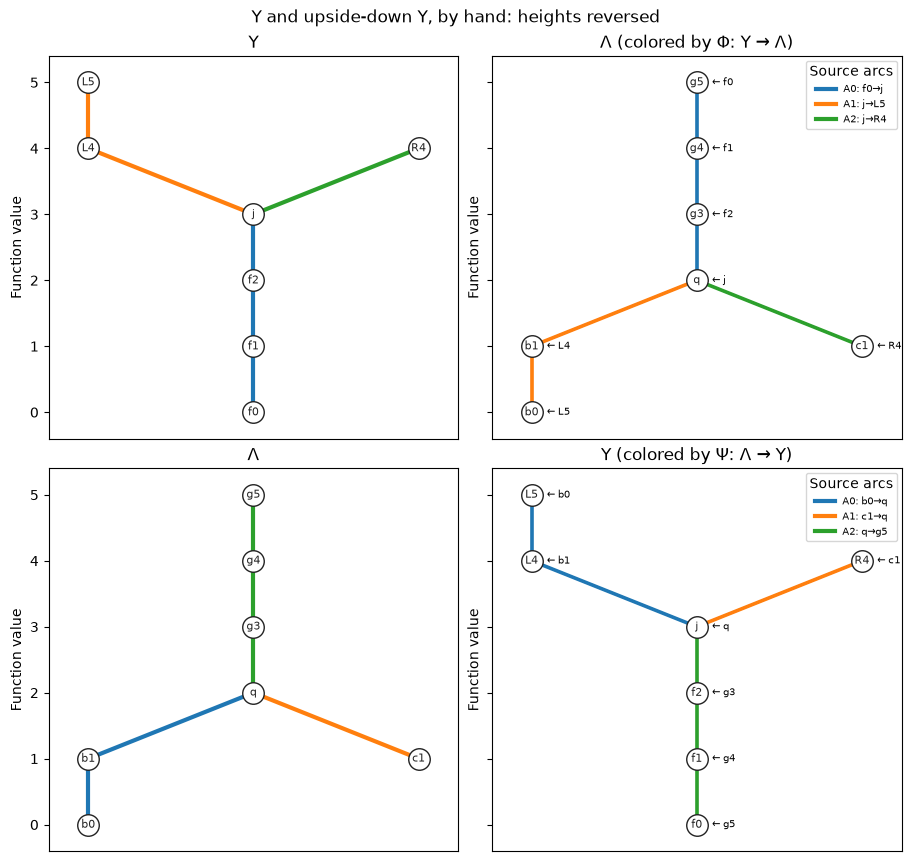

maxₓ |f(x) − g(Φ(x))| = 5.0
maxᵧ |g(y) − f(Ψ(y))| = 5.0
D = 0.0
Functional distortion = 5.0
Elapsed time: total 0.024 s (preprocessing: 0.002 s, FD map construction: 0.000 s, distortion computation: 0.021 s)


{'height_Phi_units': Fraction(5, 1),
 'height_Psi_units': Fraction(5, 1),
 'D_units': Fraction(0, 1),
 'FD_units': Fraction(5, 1),
 'height_Phi': Fraction(5, 1),
 'height_Psi': Fraction(5, 1),
 'D': Fraction(0, 1),
 'FD': Fraction(5, 1),
 'witness_height_Phi': (('v', 'f0'), ('v', 'g5')),
 'witness_height_Psi': (('v', 'g5'), ('v', 'f0')),
 'witness_D': {'segA': CSegment(origin='Phi', edge=('f0', 'f1'), index=0, F=Side(edge=('f0', 'f1'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('g4', 'g5'), vertex=None, h0=Fraction(5, 1), h1=Fraction(4, 1))),
  'segB': CSegment(origin='Phi', edge=('f0', 'f1'), index=0, F=Side(edge=('f0', 'f1'), vertex=None, h0=Fraction(0, 1), h1=Fraction(1, 1)), G=Side(edge=('g4', 'g5'), vertex=None, h0=Fraction(5, 1), h1=Fraction(4, 1))),
  'sigma': Fraction(0, 1),
  'tau': Fraction(0, 1),
  'pair': ((('v', 'f0'), ('v', 'g5')), (('v', 'f0'), ('v', 'g5'))),
  'd_f': Fraction(0, 1),
  'd_g': Fraction(0, 1)},
 'delta': 1,
 'pairs_total': 78,
 'pairs

In [8]:
def y_reversed(*, plot=True):
    start = perf_counter()
    (YF_n, YF_e, YG_n, YG_e, posF, posG) = _y_data()
    F = FunctionalDistortionGraph.from_edges(dict(YF_n), YF_e)
    G = FunctionalDistortionGraph.from_edges(dict(YG_n), YG_e)
    flip = {
        "f0": "g5",
        "f1": "g4",
        "f2": "g3",
        "j": "q",
        "L4": "b1",
        "L5": "b0",
        "R4": "c1",
    }
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    Phi = F.map_to(G, flip)
    Psi = G.map_to(F, {w: v for (v, w) in flip.items()})
    construction_time = perf_counter() - start
    r = show_maps(
        "Y and upside-down Y, by hand: heights reversed",
        F,
        G,
        Phi,
        Psi,
        posF,
        posG,
        names=("Y", "Λ"),
        figsize=(9, 8.5),
        plot=plot,
        preprocessing_time=preprocessing_time,
        construction_time=construction_time,
    )
    assert (r["height_Phi_units"], r["height_Psi_units"], r["D_units"]) == (5, 5, 0)
    return r

y_reversed()

## Y graphs with height preservation

In [9]:
def y_preserved(*, plot=True):
    start = perf_counter()
    (YF_n, YF_e, YG_n, YG_e, posF, posG) = _y_data()
    F = FunctionalDistortionGraph.from_edges(dict(YF_n), YF_e)
    G = FunctionalDistortionGraph.from_edges(dict(YG_n), YG_e)
    keep_Phi = {
        "f0": "b0",
        "f1": "b1",
        "f2": "q",
        "j": "g3",
        "L4": "g4",
        "L5": "g5",
        "R4": "g4",
    }
    keep_Psi = {
        "g5": "L5",
        "g4": "L4",
        "g3": "j",
        "q": "f2",
        "b1": "f1",
        "b0": "f0",
        "c1": "f1",
    }
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    Phi = F.map_to(G, keep_Phi)
    Psi = G.map_to(F, keep_Psi)
    construction_time = perf_counter() - start
    r = show_maps(
        "Y and upside-down Y, by hand: heights kept",
        F,
        G,
        Phi,
        Psi,
        posF,
        posG,
        names=("Y", "Λ"),
        figsize=(9, 8.5),
        plot=plot,
        preprocessing_time=preprocessing_time,
        construction_time=construction_time,
    )
    assert (r["height_Phi_units"], r["height_Psi_units"], r["D_units"]) == (
        0,
        0,
        Fr(1, 2),
    )
    return r

# y_preserved()

## Torus and line with hand-built maps

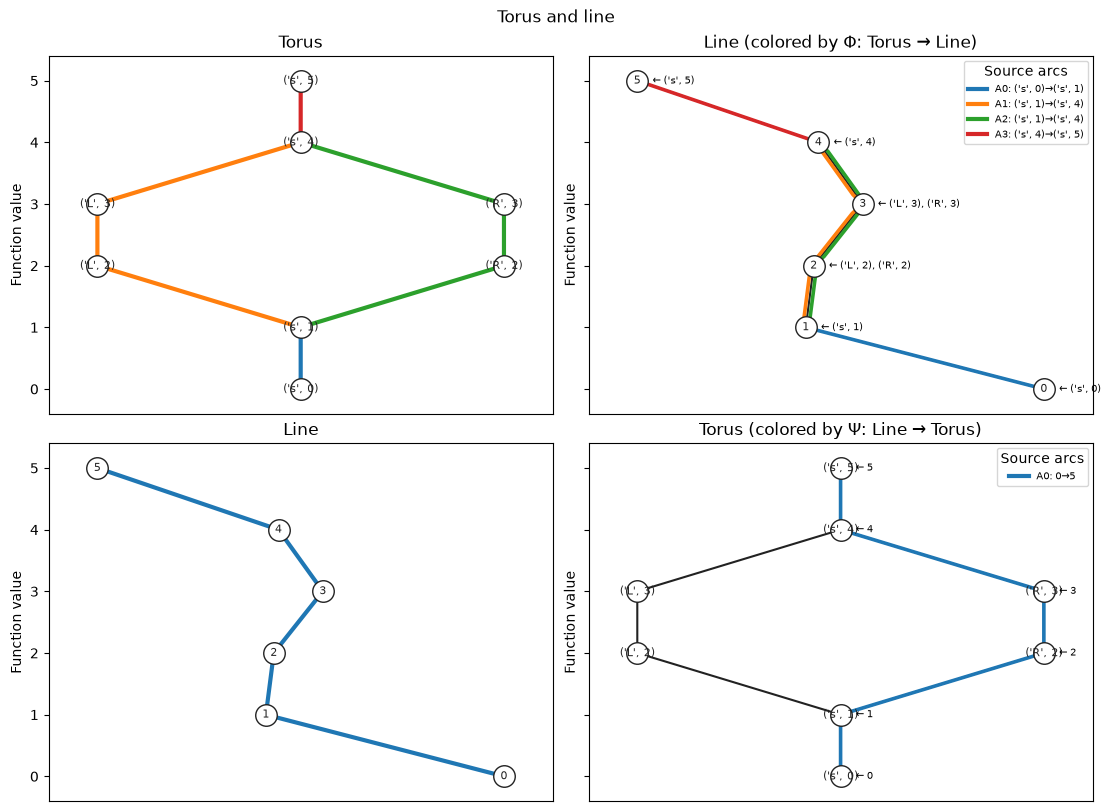

maxₓ |f(x) − g(Φ(x))| = 0.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.75
Functional distortion = 0.75
Elapsed time: total 0.007 s (preprocessing: 0.002 s, FD map construction: 0.000 s, distortion computation: 0.004 s)


In [10]:
def torus_line_example(h=3):
    """A torus with a loop of height h (two arms between heights 1 and 1 + h) and a line, both
    covering the heights 0 .. h + 2.  Phi sends every point to the point of the line at the same
    height; Psi sends the line to the path through the right arm.  Both maps keep the height,
    D = FD = h/4, and vertices alone give floor(h/2)/2."""
    start = perf_counter()
    top = h + 2
    stem = {("s", t): t for t in (0, 1, top - 1, top)}
    arms = {(side, t): t for side in ("L", "R") for t in range(2, top - 1)}
    edges = [(("s", 0), ("s", 1)), (("s", top - 1), ("s", top))]
    for side in ("L", "R"):
        chain = [("s", 1)] + [(side, t) for t in range(2, top - 1)] + [("s", top - 1)]
        edges += list(zip(chain, chain[1:]))
    F = FunctionalDistortionGraph.from_edges({**stem, **arms}, edges)
    G = FunctionalDistortionGraph.from_edges({t: t for t in range(top + 1)}, [(t, t + 1) for t in range(top)])
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    Phi = F.map_to(G, {v: t for v, t in F.f.items()})
    Psi = G.map_to(F, {t: (("R", t) if 2 <= t <= top - 2 else ("s", t)) for t in G.f})
    construction_time = perf_counter() - start
    return F, G, Phi, Psi, preprocessing_time, construction_time

F, G, Phi, Psi, preprocessing_time, construction_time = torus_line_example()
torus_hand = show_maps("Torus and line", F, G, Phi, Psi, names=("Torus", "Line"),
                       preprocessing_time=preprocessing_time,
                       construction_time=construction_time)
assert torus_hand["FD_units"] == Fr(3, 4)

## Torus and line from an interleaving

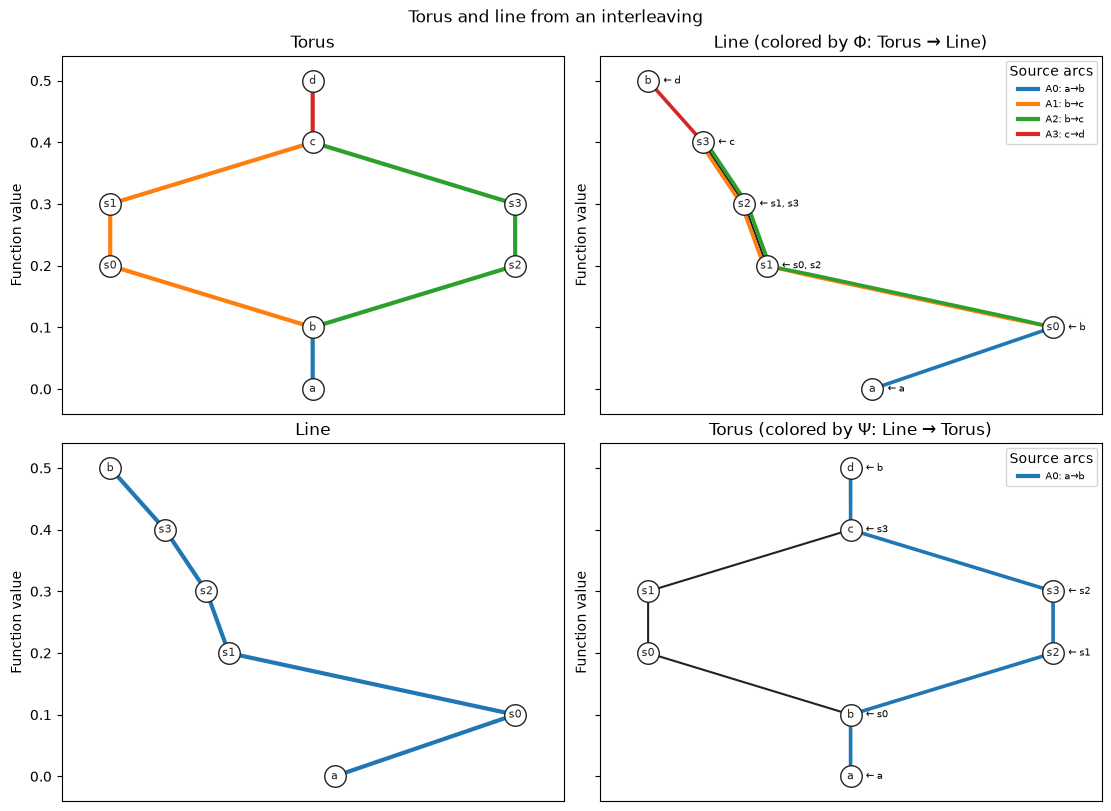

maxₓ |f(x) − g(Φ(x))| = 0.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.75
Functional distortion = 0.75
Elapsed time: total 0.190 s (preprocessing: 0.172 s, FD map construction: 0.013 s, distortion computation: 0.004 s)


In [11]:
start = perf_counter()
interleaving = Interleave(
    ex.torus(0, 1, 4, 5, delta=0.1),
    exr.line(0, 5).to_mapper(delta=0.1),
)
n = interleaving.fit()
preprocessing_time = perf_counter() - start
start = perf_counter()
maps = maps_from_interleave(interleaving, seed=0, points="close", paths="min_span")
construction_time = perf_counter() - start
torus_result = show_maps("Torus and line from an interleaving",
                         *(maps[k] for k in ("F", "G", "Phi", "Psi")), names=("Torus", "Line"), preprocessing_time=preprocessing_time,
                         construction_time=construction_time)
assert n == 1 and torus_result["FD_units"] == Fr(3, 4)

## Factor-three example

In [12]:
def tight_pair(*, plot=True):
    T = 7
    F_nodes = (
        [(f"t{k}", k) for k in range(-T, T + 1)]
        + [(f"c{k}", k) for k in range(2, T + 1)]
        + [("u1", 1), ("u2", 2)]
        + [(f"d{k}", k) for k in range(-T, -1)]
        + [("l-1", -1), ("l-2", -2)]
    )
    F_edges = (
        [(f"t{k}", f"t{k + 1}") for k in range(-T, T)]
        + [(f"c{k}", f"c{k + 1}") for k in range(2, T)]
        + [("u1", "c2"), ("u1", "u2"), ("u2", "t3")]
        + [(f"d{k}", f"d{k + 1}") for k in range(-T, -2)]
        + [("l-1", "d-2"), ("l-1", "l-2"), ("l-2", "t-3")]
    )
    G_nodes = (
        [(f"g{k}", k) for k in range(-T, T + 1)]
        + [(f"a{k}", k) for k in range(1, T + 1)]
        + [(f"b{k}", k) for k in range(-T, 0)]
    )
    G_edges = (
        [(f"g{k}", f"g{k + 1}") for k in range(-T, T)]
        + [("g0", "a1")]
        + [(f"a{k}", f"a{k + 1}") for k in range(1, T)]
        + [("g0", "b-1")]
        + [(f"b{k}", f"b{k + 1}") for k in range(-T, -1)]
    )
    start = perf_counter()
    I5 = Interleave(make_graph(F_nodes, F_edges), make_graph(G_nodes, G_edges))
    n = I5.fit()
    # print("interleaving n =", n)
    preprocessing_time = perf_counter() - start
    start = perf_counter()
    m5 = maps_from_interleave(I5, seed=0, points="close", paths="min_span")
    construction_time = perf_counter() - start
    (F5, G5, Phi5, Psi5) = (m5["F"], m5["G"], m5["Phi"], m5["Psi"])
    xF = {"t": 0, "c": -1.5, "u": -0.75, "d": 1.5, "l": 0.75}
    posF5 = {
        v: (xF[v[0]] * (1.2 if v in ("u1", "l-1") else 1), h)
        for (v, h) in F5.f.items()
    }
    xG = {"g": 0, "a": -1.2, "b": 1.2}
    posG5 = {v: (xG[v[0]], h) for (v, h) in G5.f.items()}
    r5 = show_maps(
        "The tight pair (n = 1)",
        F5,
        G5,
        Phi5,
        Psi5,
        posF5,
        posG5,
        figsize=(10, 15),
        plot=plot,
        preprocessing_time=preprocessing_time,
        construction_time=construction_time,
    )
    assert r5["D_units"] == 3 and r5["FD_units"] == 3
    return r5

# Uncomment to run this example.
# tight_pair()

## A larger pair

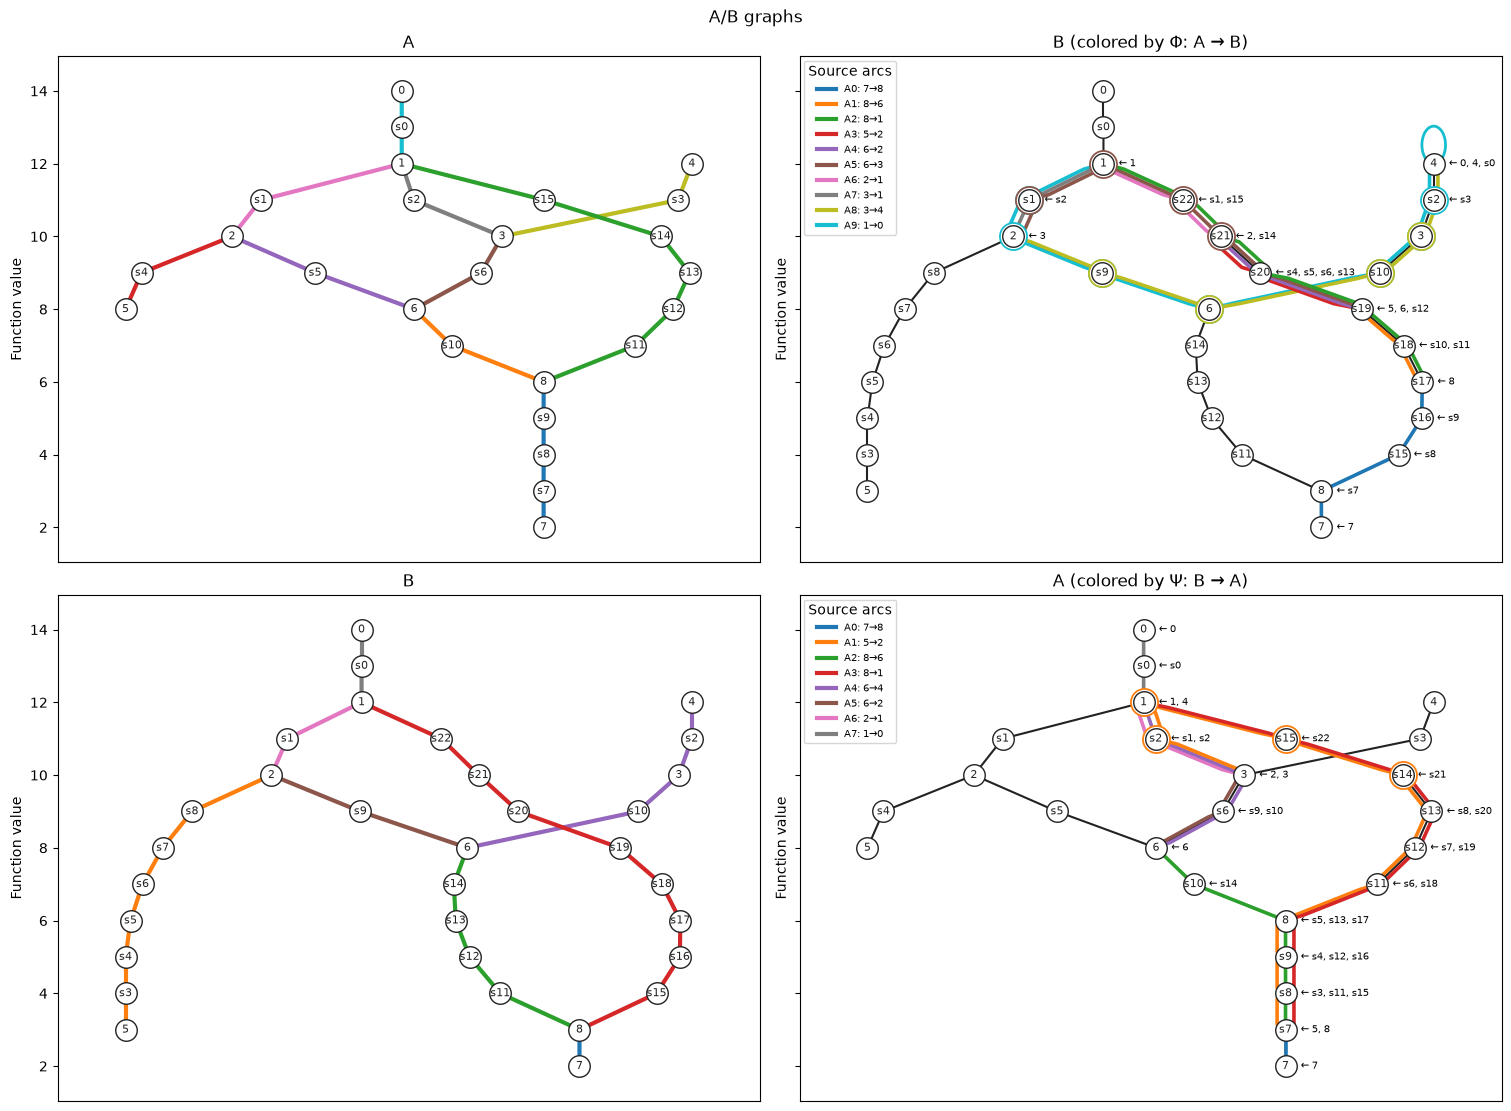

maxₓ |f(x) − g(Φ(x))| = 4.0
maxᵧ |g(y) − f(Ψ(y))| = 2.0
D = 3.5
Functional distortion = 4.0
Elapsed time: total 4.078 s (preprocessing: 2.458 s, FD map construction: 0.344 s, distortion computation: 1.276 s)


In [13]:
start = perf_counter()
large_interleaving = Interleave(ex.interleave_example_A(), ex.interleave_example_B())
large_n = large_interleaving.fit()
preprocessing_time = perf_counter() - start
start = perf_counter()
large_maps = maps_from_interleave(large_interleaving, seed=0)
construction_time = perf_counter() - start
# print("Interleaving parameter:", large_n)
large_result = show_maps("A/B graphs", *(large_maps[k] for k in ("F", "G", "Phi", "Psi")),
                         names=("A", "B"), figsize=(15, 11), preprocessing_time=preprocessing_time,
                         construction_time=construction_time)